In [1]:
# Customer Segmentation using K-Means Clustering

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


In [2]:
# Load dataset
df = pd.read_csv("D:\\powerbi\\Mall_Customers.csv")
df.rename(columns={'Annual Income (k$)': 'AnnualIncome', 'Spending Score (1-100)': 'SpendingScore'}, inplace=True)
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

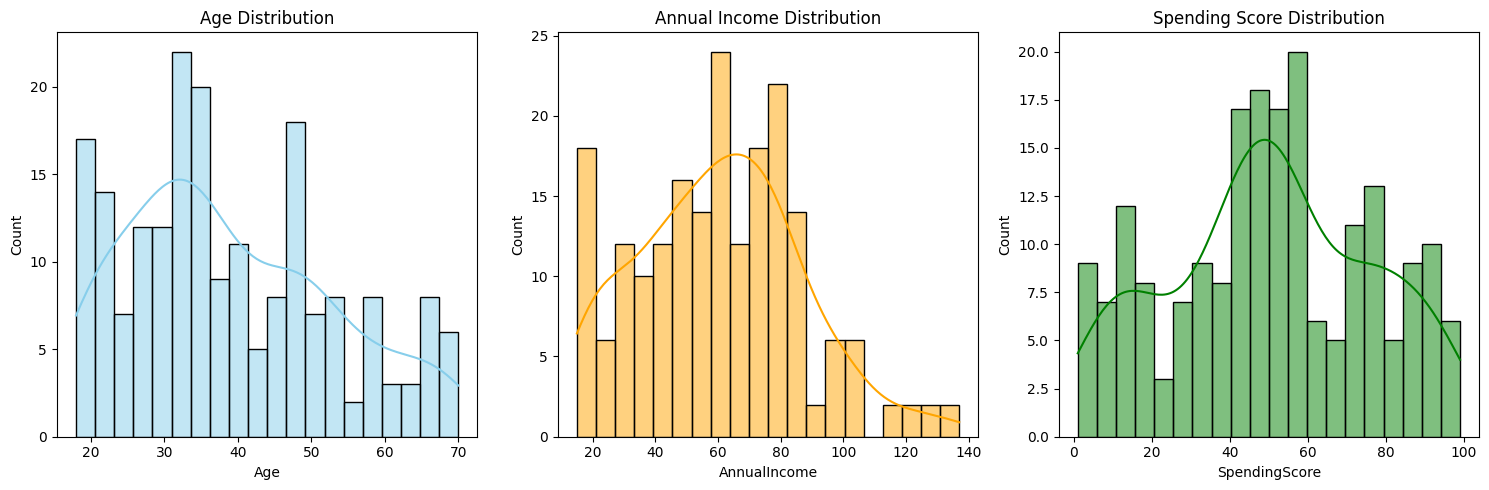

In [3]:
# EDA plots
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True, bins=20, color='skyblue')
plt.title('Age Distribution')

plt.subplot(1, 3, 2)
sns.histplot(df['AnnualIncome'], kde=True, bins=20, color='orange')
plt.title('Annual Income Distribution')

plt.subplot(1, 3, 3)
sns.histplot(df['SpendingScore'], kde=True, bins=20, color='green')
plt.title('Spending Score Distribution')

plt.tight_layout()
plt.show()

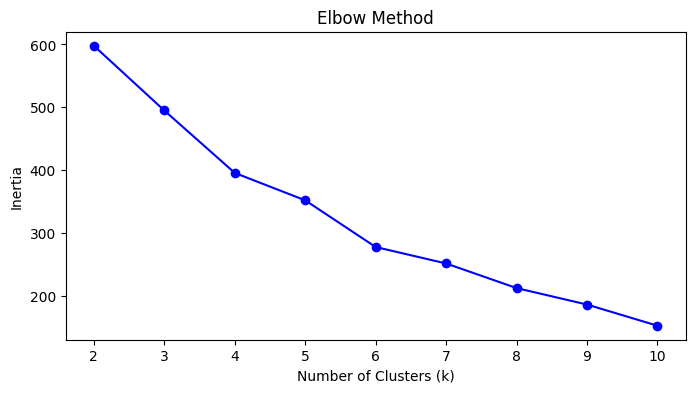

In [4]:
# Feature selection and scaling
features = df[['Gender', 'Age', 'AnnualIncome', 'SpendingScore']]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Elbow method
inertia = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

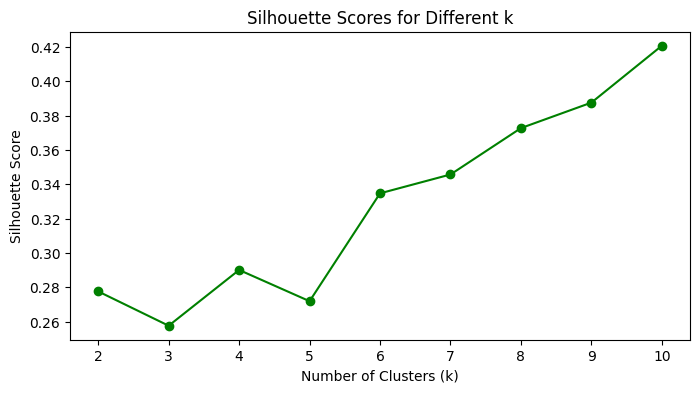

In [5]:
# Silhouette score
silhouette_scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, 'go-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different k')
plt.show()

In [6]:
# Final KMeans
k_optimal = 5
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled_features)


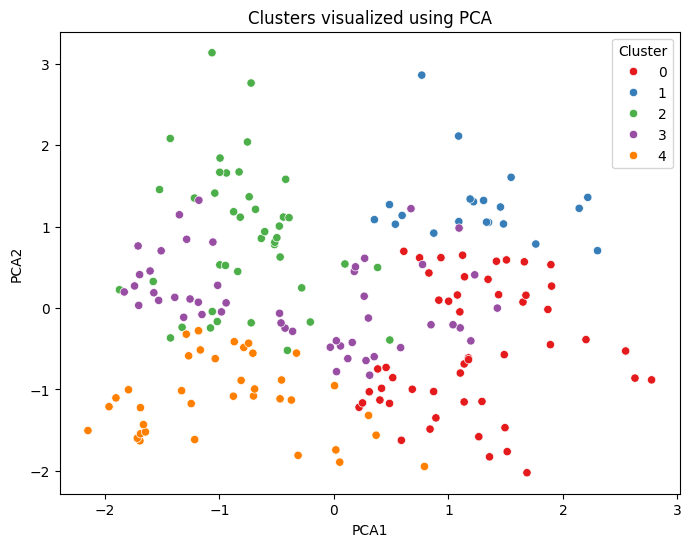

In [7]:
# PCA visualization
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)
df['PCA1'] = pca_features[:, 0]
df['PCA2'] = pca_features[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='Cluster', palette='Set1')
plt.title('Clusters visualized using PCA')
plt.show()


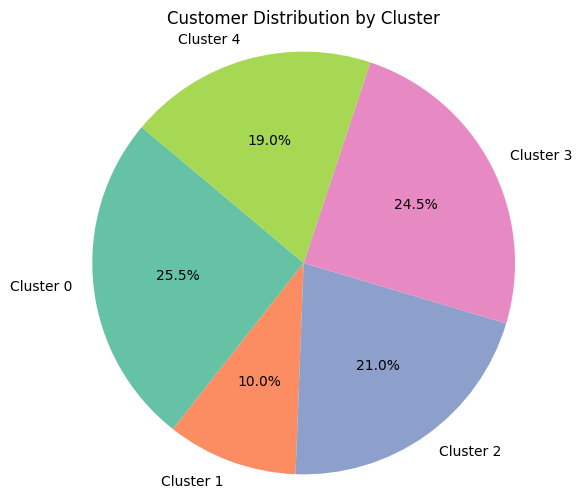

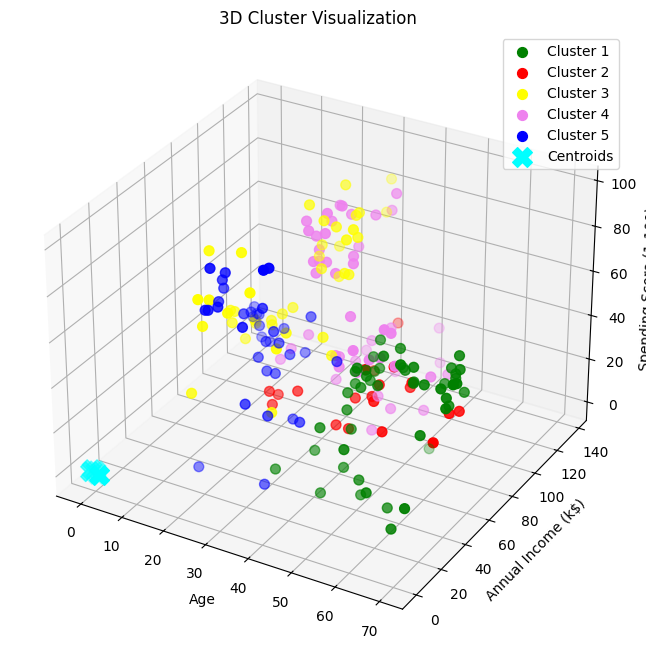

In [8]:
# Pie chart of cluster distribution
cluster_counts = df['Cluster'].value_counts().sort_index()
plt.figure(figsize=(6,6))
plt.pie(cluster_counts, labels=[f'Cluster {i}' for i in cluster_counts.index],
        autopct='%1.1f%%', startangle=140, colors=plt.cm.Set2.colors)
plt.title("Customer Distribution by Cluster")
plt.axis('equal')
plt.show()

# Prepare features for 3D plot
X_3d = df[['Age', 'AnnualIncome', 'SpendingScore']].values

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Assign cluster colors (same style as 2D plot)
colors = ['green', 'red', 'yellow', 'violet', 'blue']

for cluster in range(k_optimal):
    ax.scatter(X_3d[df['Cluster'] == cluster, 0],
               X_3d[df['Cluster'] == cluster, 1],
               X_3d[df['Cluster'] == cluster, 2],
               s=50,
               c=colors[cluster],
               label=f'Cluster {cluster+1}')

# Plot centroids
ax.scatter(kmeans.cluster_centers_[:, 1],  # Age
           kmeans.cluster_centers_[:, 2],  # Annual Income
           kmeans.cluster_centers_[:, 3],  # Spending Score
           s=200,
           c='cyan',
           label='Centroids',
           marker='X')

ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')
ax.set_title('3D Cluster Visualization')
ax.legend()
plt.show()

In [9]:
# Cluster profiling
df_summary = df.groupby('Cluster').agg({
    'Age': ['mean', 'min', 'max'],
    'AnnualIncome': ['mean', 'min', 'max'],
    'SpendingScore': ['mean', 'min', 'max'],
    'Gender': 'mean'
}).reset_index()
df_summary.columns = ['Cluster', 'Age_Mean', 'Age_Min', 'Age_Max',
                      'Income_Mean', 'Income_Min', 'Income_Max',
                      'Score_Mean', 'Score_Min', 'Score_Max',
                      'Gender_Female_Ratio']

print("\nCluster Profiles:")
print(df_summary)


Cluster Profiles:
   Cluster   Age_Mean  Age_Min  Age_Max  Income_Mean  Income_Min  Income_Max  \
0        0  56.470588       37       70    46.098039          19          75   
1        1  39.500000       19       59    85.150000          71         137   
2        2  28.690476       18       40    60.904762          15         137   
3        3  37.897959       23       56    82.122449          54         126   
4        4  27.315789       18       43    38.842105          16          65   

   Score_Mean  Score_Min  Score_Max  Gender_Female_Ratio  
0   39.313725          3         60             0.490196  
1   14.050000          1         36             0.000000  
2   70.238095         35         97             0.000000  
3   54.448980          7         95             1.000000  
4   56.210526          6         99             1.000000  


In [10]:
# Marketing recommendations
recommendations = {
    0: "Target with luxury products and premium loyalty offers.",
    1: "Promote budget-friendly deals and student discounts.",
    2: "Focus on family packages and community events.",
    3: "Upsell new arrivals and trend-focused collections.",
    4: "Introduce exclusive membership benefits and VIP events."
}

print("\nMarketing Recommendations:")
for cluster_id, rec in recommendations.items():
    print(f"Cluster {cluster_id}: {rec}")



Marketing Recommendations:
Cluster 0: Target with luxury products and premium loyalty offers.
Cluster 1: Promote budget-friendly deals and student discounts.
Cluster 2: Focus on family packages and community events.
Cluster 3: Upsell new arrivals and trend-focused collections.
Cluster 4: Introduce exclusive membership benefits and VIP events.
